# 05 · External cohort and survival: two negative results

> Part of the spatial-niche-gbm walk-through. The project is a **benchmark**: it tests whether spatial graph neural networks improve supervised niche prediction in glioblastoma Visium data over matched graph-free models (they do not). See `docs/00_overview_and_roadmap.md`. Notebooks read `data/` (see `docs/WORKFLOW.md`, step A) and the tracked `results/`; none of them trains a model.

The seed-7 fixed-split model is applied, without retraining, to the Greenwald et al. (2024) Visium cohort.
Separately, a niche-signature score is tested against overall survival in TCGA-GBM. Both results are
negative, and the paper reports them as such.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()          # run from notebooks/
PRE = REPO / "data" / "preprocessed"
RES = REPO / "results"
NICHES = ["immune_cold", "immune_hot", "normal", "necrotic"]
COLORS = {"immune_cold": "#D55E00", "immune_hot": "#0072B2", "normal": "#009E73",
          "necrotic": "#CC79A7", "exclude": "#DDDDDD"}
pd.set_option("display.precision", 3)
from lifelines import KaplanMeierFitter

## 1. Greenwald cohort (13 samples)

External inputs are scaled exactly like the training matrix: log1p of counts at 100,000 per spot.

In [2]:
def composition(path):
    s = json.load(open(path)); n = sum(v["n_spots"] for v in s.values())
    return pd.Series({c: sum(v[f"frac_{c}"] * v["n_spots"] for v in s.values()) / n for c in NICHES}), s
comp, ext = composition(RES / "external_v2" / "greenwald_summary.json")
comp10k, _ = composition(RES / "external_v2_ts1e4" / "greenwald_summary.json")
ext_df = pd.DataFrame(ext).T
print(f"{len(ext_df)} samples, {int(ext_df.n_spots.sum()):,} spots")
pd.DataFrame({"matched scaling (CP100k)": comp, "mis-scaled (CP10k)": comp10k}).round(3)

13 samples, 25,488 spots


,matched scaling (CP100k),mis-scaled (CP10k)
immune_cold,0.008,0.022
immune_hot,0.778,0.403
normal,0.014,0.014
necrotic,0.200,0.561


In [3]:
ext_df[["region", "n_spots"] + [f"frac_{c}" for c in NICHES]].sort_values("region")

,region,n_spots,frac_immune_cold,frac_immune_hot,frac_normal,frac_necrotic
GBM_ZH8811Abulk,bulk,2486,0.0,0.613,0.0,0.387
GBM_ZH8811Bbulk,bulk,2595,0.0,0.559,0.0,0.441
GBM_ZH8812bulk,bulk,2343,0.085,0.878,0.003,0.034
GBM_ZH916bulk,bulk,2199,0.0,0.463,0.004,0.533
GBM_ZH1019T1,contrast_enhancing,1112,0.0,0.924,0.0,0.076
GBM_ZH881T1,contrast_enhancing,2792,0.0,0.87,0.0,0.13
GBM_ZH916T1,contrast_enhancing,2780,0.0,0.719,0.0,0.281
GBM_ZH1007inf,infiltrating,1436,0.0,1.0,0.0,0.0
GBM_ZH1019inf,infiltrating,1726,0.0,0.941,0.0,0.059
GBM_ZH881_inf,infiltrating,1387,0.0,0.876,0.03,0.094


**The niche classifier does not transfer.** About 78% of external spots are predicted immune-hot and
almost none immune-cold, although immune-cold is the majority class in the SNUH test patients and is
expected to be abundant in bulk tumour. Predictions also do not follow the annotated sampling region.
Rescaling the input (CP10k instead of CP100k) flips the predicted class balance toward necrotic, so the
classifier is not calibrated for this cohort.

In [4]:
r = ext_df.assign(r=ext_df.mes_pearson_vs_neftel.astype(float))
print(f"per-sample MES r vs Neftel meta-module: mean {r.r.mean():.2f}, median {r.r.median():.2f}, range {r.r.min():.2f} to {r.r.max():.2f}")
r.groupby("region").r.agg(["mean", "size"]).round(2)

per-sample MES r vs Neftel meta-module: mean 0.21, median 0.15, range -0.35 to 0.58


,mean,size
region,,
bulk,0.37,4
contrast_enhancing,0.37,3
infiltrating,0.01,4
necrotic,0.44,1
unknown,-0.35,1


**The MES head transfers partially.** Its per-sample correlation with the Neftel MES meta-module
averages 0.21. It is moderate where malignant cells are dense (bulk, contrast-enhancing) and near zero at
the infiltrating edge. A pooled spot-level correlation looks much higher, but it is driven by differences
*between* samples and is not evidence of within-sample agreement.

## 2. TCGA-GBM survival

No Visium GBM cohort with matched survival exists. The survival test therefore uses fixed niche gene
signatures, combined with the pseudo-risk weights, scored on bulk RNA-seq. It does **not** use the trained
network.

In [5]:
t3 = json.load(open(RES / "tables" / "main" / "Table3_survival_results.json"))
fmt = lambda d: f"{d['HR']:.3f} ({d['ci'][0]:.3f}-{d['ci'][1]:.3f}), " + ("p < 0.001" if d["p"] < 1e-3 else f"p = {d['p']:.3f}")
pd.Series({"samples / patients / events": f"{t3['n']} / {t3['n_patients']} / {t3['events']}",
           "Cox HR per SD (univariate)": fmt(t3["cox_univariate_per_sd"]),
           "Cox HR per SD (age-adjusted)": fmt(t3["cox_age_adjusted_per_sd"]),
           "concordance index": f"{t3['c_index']:.2f}",
           "log-rank p (median split)": f"{t3['km_logrank_p']:.2f}",
           "median OS high vs low (days)": f"{t3['km_median_os_high']:.0f} vs {t3['km_median_os_low']:.0f}",
           "positive control: age, HR per SD": fmt(t3["positive_control_age_per_sd"]),
           "smallest detectable HR per SD (80% power)": f"{t3['min_detectable_HR_per_sd_80pct_power']:.2f}"}, name="Table 3").to_frame()

,Table 3
samples / patients / events,166 / 165 / 132
Cox HR per SD (univariate),"1.121 (0.923-1.362), p = 0.250"
Cox HR per SD (age-adjusted),"1.025 (0.836-1.256), p = 0.813"
concordance index,0.52
log-rank p (median split),0.42
median OS high vs low (days),424 vs 444
"positive control: age, HR per SD","1.554 (1.279-1.888), p < 0.001"
smallest detectable HR per SD (80% power),1.28


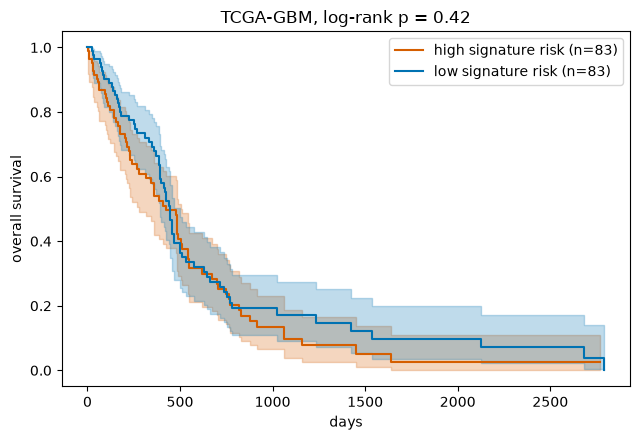

In [6]:
tc = pd.read_csv(RES / "tables" / "supplement" / "TableS4_tcga_scores_clinical.csv")
high = tc.risk > tc.risk.median()
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for mask, name, col in [(high, "high signature risk", "#D55E00"), (~high, "low signature risk", "#0072B2")]:
    KaplanMeierFitter().fit(tc.os_days[mask], tc.os_event[mask], label=f"{name} (n={mask.sum()})").plot_survival_function(ax=ax, color=col)
ax.set_xlabel("days"); ax.set_ylabel("overall survival"); ax.set_title(f"TCGA-GBM, log-rank p = {t3['km_logrank_p']:.2f}")
plt.tight_layout(); plt.show()

The score does not stratify survival: HR 1.12 per SD, p = 0.25. This is a **bounded** null. Age, run
through the same pipeline, is recovered at 1.55 per SD, so the pipeline can detect a real prognostic
covariate. With 132 events, effects smaller than about 1.28 per SD could not have been detected. The
correct reading is that any prognostic effect of bulk niche composition is smaller than that, not that it
is zero.